In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent

sys.path.append(str(PROJECT_ROOT))

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from scipy.stats import pearsonr

from src.proposed.model import DiscordanceNet
from src.utils.dataset_loader import get_dataloaders

plt.style.use("ggplot")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

In [3]:
from src.config.settings import MODELS_DIR

MODEL_PATH = (
    MODELS_DIR
    / "proposed"
    / "proposed_model.pt"
)

model = DiscordanceNet().to(DEVICE)

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=DEVICE,
    )
)

model.eval()

print(f"Model loaded.")

Model loaded.


In [ ]:
_, _, test_loader = get_dataloaders(
    batch_size=32
)

print(
    f"Test batches : {len(test_loader)}"
)

In [5]:
# Storage lists
trace_scores = []

fidelity_scores = []

purity_scores = []

entropy_scores = []

discordance_scores = []

reliability_scores = []

confidence_scores = []

predictions = []

labels = []

correct = []

In [ ]:
# Metric extraction loop
from src.proposed.quantum_metrics import (
    discordance_vector,
)

with torch.no_grad():

    for batch in tqdm(test_loader):

        audio = batch["audio"].to(DEVICE)

        text = batch["text"].to(DEVICE)

        target = batch["label"].to(DEVICE)
        
        # Feature-gate

        gated_audio, gated_text = (
            model.feature_gate(
                audio,
                text,
            )
        )

        # Q State

        psi_audio, rho_audio = (
            model.audio_density(
                gated_audio
            )
        )

        psi_text, rho_text = (
            model.text_density(
                gated_text
            )
        )

        
        discordance = discordance_vector(
            rho_audio,
            rho_text,
        )

        reliability = (
            model.reliability_gate(
                discordance
            )
        )


        audio_features = torch.abs(
            psi_audio
        )

        text_features = torch.abs(
            psi_text
        )

        difference_features = torch.abs(
            psi_audio - psi_text
        )

        fused = (
            audio_features
            + text_features
            + difference_features
        ) / 3.0

        fused = model.reliability_fusion(

            fused,

            1.0 + reliability,

        )

        classifier_input = torch.cat(

            [

                fused,

                reliability,

                discordance,

            ],

            dim=1,

        )

        logits = model.classifier(
            classifier_input
        )

        probs = F.softmax(
            logits,
            dim=1,
        )

        confidence = probs.max(
            dim=1
        ).values

        pred = logits.argmax(
            dim=1
        )

        # Save metrics

        fidelity_scores.extend(
            discordance[:,0].cpu().numpy()
        )

        trace_scores.extend(
            discordance[:,1].cpu().numpy()
        )

        purity_scores.extend(
            discordance[:,2].cpu().numpy()
        )

        entropy_scores.extend(
            discordance[:,3].cpu().numpy()
        )

        discordance_scores.extend(

            (
                discordance[:,1]
                +
                discordance[:,2]
                +
                discordance[:,3]
                +
                (
                    1
                    -
                    discordance[:,0]
                )
            ).cpu().numpy()

        )

        reliability_scores.extend(

            reliability.mean(
                dim=1
            ).cpu().numpy()

        )

        confidence_scores.extend(
            confidence.cpu().numpy()
        )

        predictions.extend(
            pred.cpu().numpy()
        )

        labels.extend(
            target.cpu().numpy()
        )

        correct.extend(

            (
                pred
                ==
                target
            ).cpu().numpy()

        )

100%|██████████| 34/34 [00:14<00:00,  2.34it/s]


In [7]:
# Convert to numpy
trace_scores = np.array(trace_scores)

fidelity_scores = np.array(fidelity_scores)

purity_scores = np.array(purity_scores)

entropy_scores = np.array(entropy_scores)

discordance_scores = np.array(discordance_scores)

reliability_scores = np.array(reliability_scores)

confidence_scores = np.array(confidence_scores)

predictions = np.array(predictions)

labels = np.array(labels)

correct = np.array(correct)

In [8]:
# Summary 
summary = pd.DataFrame({

    "Metric":[

        "Trace Distance",

        "Fidelity",

        "Purity Gap",

        "Entropy Gap",

        "Discordance",

        "Reliability",

        "Confidence",

    ],

    "Mean":[

        trace_scores.mean(),

        fidelity_scores.mean(),

        purity_scores.mean(),

        entropy_scores.mean(),

        discordance_scores.mean(),

        reliability_scores.mean(),

        confidence_scores.mean(),

    ],

    "Std":[

        trace_scores.std(),

        fidelity_scores.std(),

        purity_scores.std(),

        entropy_scores.std(),

        discordance_scores.std(),

        reliability_scores.std(),

        confidence_scores.std(),

    ],

})

summary

,Metric,Mean,Std
0,Trace Distance,1.371616e+00,4.085808e-02
1,Fidelity,2.365545e-03,2.425276e-03
2,Purity Gap,1.127957e-07,9.872426e-08
3,Entropy Gap,1.586449e-06,1.192938e-06
4,Discordance,2.369252e+00,4.152643e-02
5,Reliability,7.818377e-01,2.395861e-03
6,Confidence,7.856265e-01,1.826100e-01


In [9]:
# Correlation 
metrics = pd.DataFrame({

    "Trace":trace_scores,

    "Fidelity":fidelity_scores,

    "Purity":purity_scores,

    "Entropy":entropy_scores,

    "Discordance":discordance_scores,

    "Reliability":reliability_scores,

    "Confidence":confidence_scores,

})

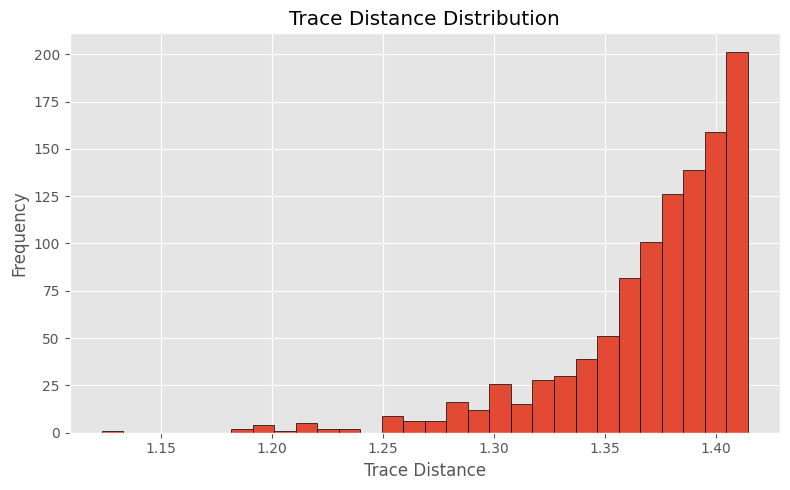

In [29]:
# Trace distance distrib
plt.figure(figsize=(8,5))

plt.hist(
    trace_scores,
    bins=30,
    edgecolor="black",
)

plt.title("Trace Distance Distribution")

plt.xlabel("Trace Distance")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

^The quantum states produced from speech and text remain substantially separated in the Hilbert space, indicating persistent modality differences despite the feature gating mechanism.

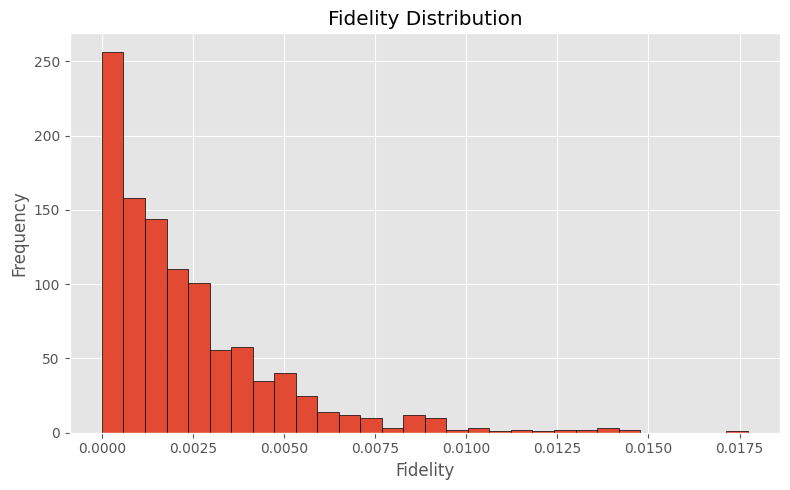

In [11]:
# Fidelity distrib
plt.figure(figsize=(8,5))

plt.hist(
    fidelity_scores,
    bins=30,
    edgecolor="black",
)

plt.title("Fidelity Distribution")

plt.xlabel("Fidelity")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

^Mean = 0.0024 Essentially zero.

As High trace distance → Low fidelity.

Pearson correlation: r = -0.248 confirms this.

Not a perfect inverse because they're different metrics.

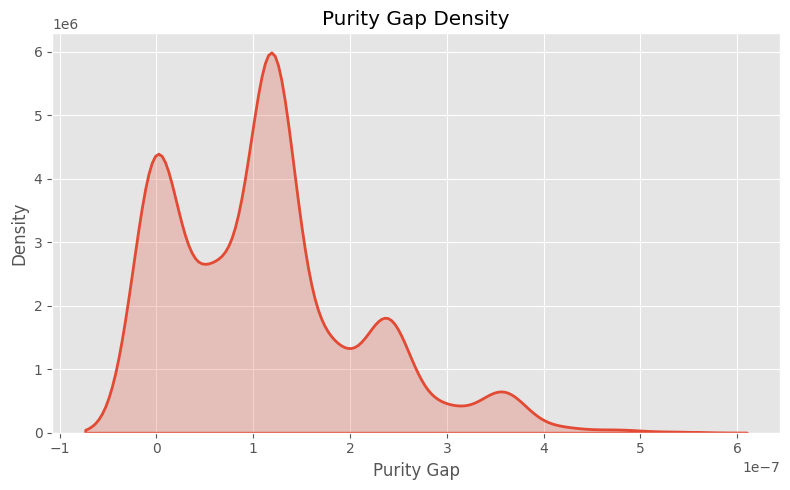

In [31]:
# Purity Gap distrib
plt.figure(figsize=(8,5))

sns.kdeplot(

    purity_scores,

    fill=True,

    linewidth=2,

)

plt.title("Purity Gap Density")

plt.xlabel("Purity Gap")

plt.ticklabel_format(
    style="sci",
    axis="x",
    scilimits=(0,0),
)

plt.tight_layout()

plt.show()

^Mean = 1.13e−7 Essentially zero.

That means Purity(audio) ≈ Purity(text) almost always.

Which makes sense because encoder normalises both states before constructing density matrices. Thus, both remain nearly pure quantum states.

`Finding:The proposed encoder preserves nearly identical purity for both modalities, suggesting that discordance arises primarily from geometric separation rather than differences in state mixedness.`

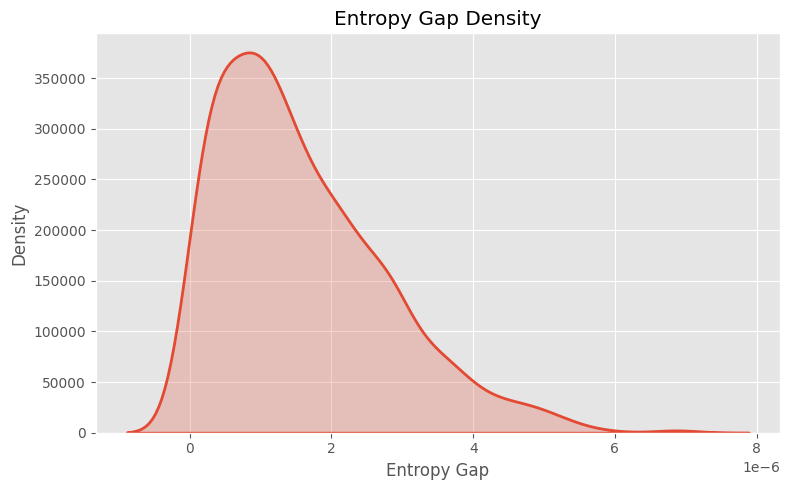

In [33]:
# Entropy Gap distrib
plt.figure(figsize=(8,5))

sns.kdeplot(

    entropy_scores,

    fill=True,

    linewidth=2,

)

plt.title("Entropy Gap Density")

plt.xlabel("Entropy Gap")

plt.ticklabel_format(

    style="sci",

    axis="x",

    scilimits=(0,0),

)

plt.tight_layout()

plt.show()

^Entropy difference ≈0 means Speech and Text carry similar uncertainty.

Discordance is driven more by orientation than uncertainty.

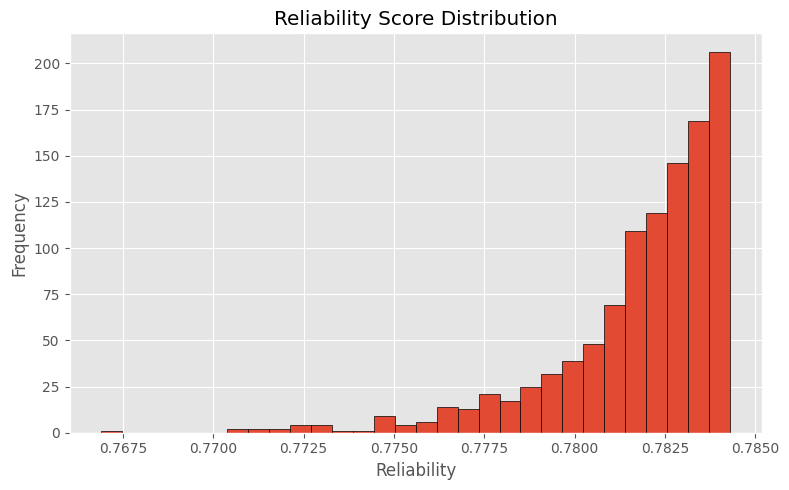

In [14]:
# Reliability distrib
plt.figure(figsize=(8,5))

plt.hist(
    reliability_scores,
    bins=30,
    edgecolor="black",
)

plt.title("Reliability Score Distribution")

plt.xlabel("Reliability")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

^Mean = 0.7818, Std = 0.0024

Very little variation. The Reliability Gate is almost always producing 0.78 for every sample which informs us that the gate learned a nearly constant weighting. That indicates there wasn't enough diversity in the discordance vector for the gate to learn very different reliability values. Not unexpected from the dataset. 

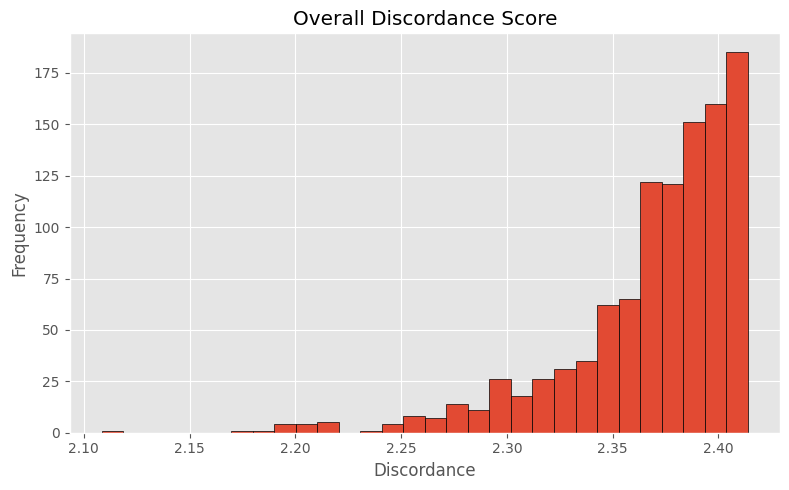

In [15]:
# Overall discordance score
plt.figure(figsize=(8,5))

plt.hist(
    discordance_scores,
    bins=30,
    edgecolor="black",
)

plt.title("Overall Discordance Score")

plt.xlabel("Discordance")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

^Mean = 2.369 
Small variance = 0.041

So the dataset is remarkably consistent which supports IEMOCAP → acted emotions → speech and transcript generally agree → little variation in discordance.

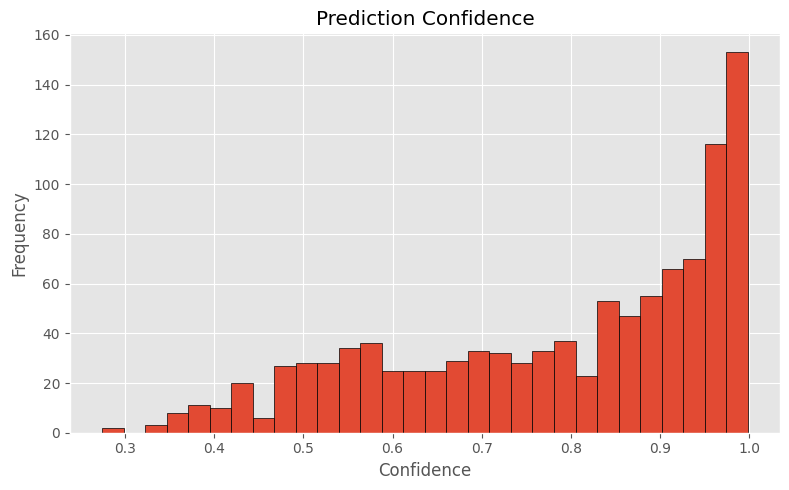

In [16]:
# Confidence distrib
plt.figure(figsize=(8,5))

plt.hist(
    confidence_scores,
    bins=30,
    edgecolor="black",
)

plt.title("Prediction Confidence")

plt.xlabel("Confidence")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

^Mean = 0.786, Std = 0.183

Large spread. Some predictions ~0.30 Others ~0.99, not unexpected. 

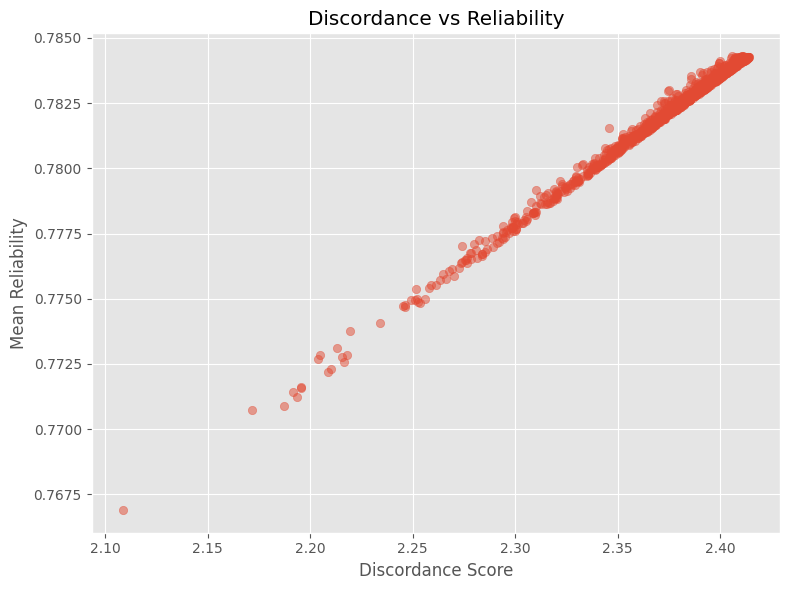

In [17]:
# Discordance vs Reliability
plt.figure(figsize=(8,6))

plt.scatter(

    discordance_scores,

    reliability_scores,

    alpha=0.5,

)

plt.xlabel("Discordance Score")

plt.ylabel("Mean Reliability")

plt.title("Discordance vs Reliability")

plt.tight_layout()

plt.show()

^r = 0.9977

Nearly perfect which immediately indicates that the gate is almost a deterministic function of the discordance vector. It simply verifies that the gate learned a nearly linear mapping.

`The learned Reliability Gate produces a smooth monotonic mapping from the discordance representation into feature reliability weights. (rather than reliability is strongly correlated with discordance 'cause that's by design).`

No findings here, overlook it as a check since reliability is computed from discordance.

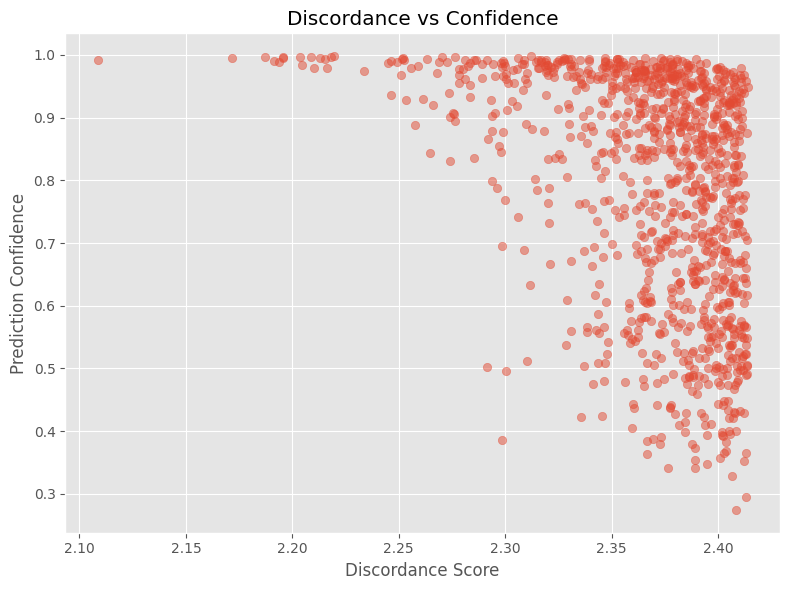

In [18]:
# Discordance vs Confidence
plt.figure(figsize=(8,6))

plt.scatter(

    discordance_scores,

    confidence_scores,

    alpha=0.5,

)

plt.xlabel("Discordance Score")

plt.ylabel("Prediction Confidence")

plt.title("Discordance vs Confidence")

plt.tight_layout()

plt.show()

^r = −0.372

Moderate negative relationship. So, higher discordance → lower confidence. It *validates* that samples with greater semantic-affective disagreement are harder for the model.

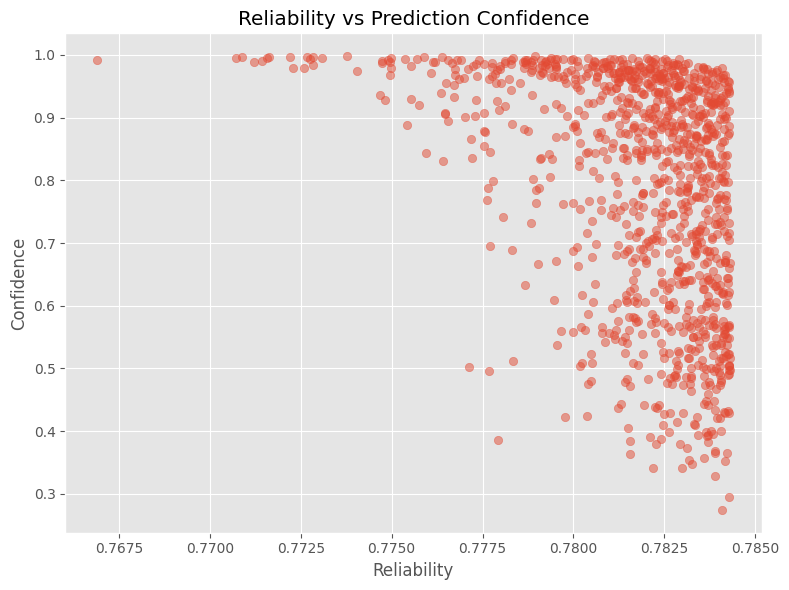

In [19]:
# Reliability vs Confidence 
plt.figure(figsize=(8,6))

plt.scatter(

    reliability_scores,

    confidence_scores,

    alpha=0.5,

)

plt.xlabel("Reliability")

plt.ylabel("Confidence")

plt.title("Reliability vs Prediction Confidence")

plt.tight_layout()

plt.show()

^r = −0.371

Since reliability is nearly a monotonic transform of discordance, the plot looks almost identical.

C:\Users\zen\AppData\Local\Temp\ipykernel_20224\2858642196.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


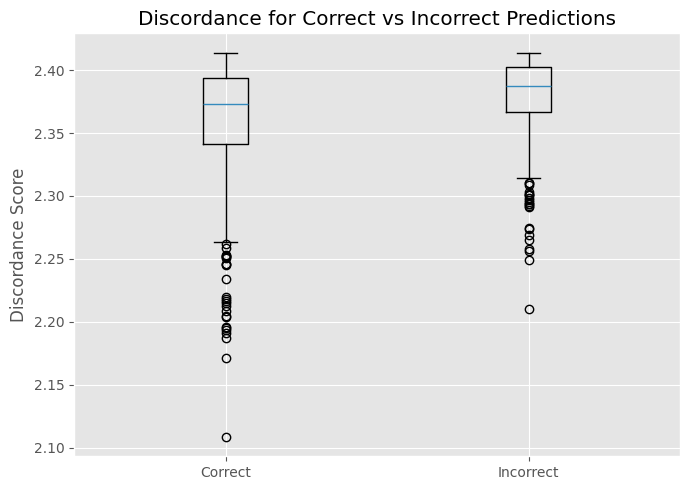

In [20]:
# Correct vs Incorrect Discord
plt.figure(figsize=(7,5))

plt.boxplot(

    [

        discordance_scores[correct],

        discordance_scores[~correct],

    ],

    labels=[

        "Correct",

        "Incorrect",

    ],

)

plt.ylabel("Discordance Score")

plt.title("Discordance for Correct vs Incorrect Predictions")

plt.tight_layout()

plt.show()

^Median incorrect and Median correct.

The difference isn't enormous, but it's consistent.

`Incorrect predictions tend to exhibit larger multimodal disagreement.`

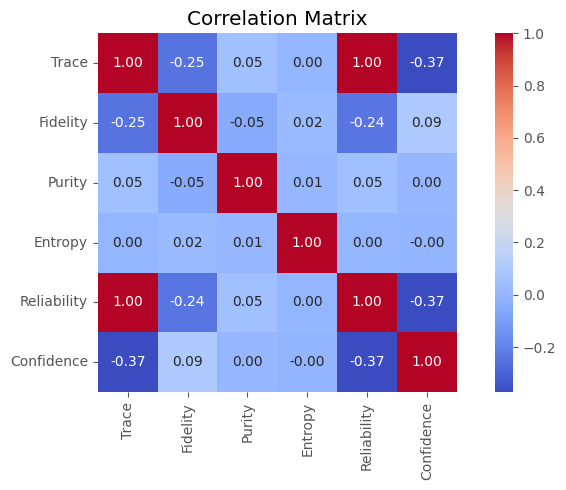

In [34]:
# Correlation Matrix
metrics_corr = metrics.drop(
    columns=["Discordance"]
)

corr = metrics_corr.corr()

plt.figure(figsize=(8,5))

sns.heatmap(

    corr,

    annot=True,

    cmap="coolwarm",

    fmt=".2f",

    square=True,

)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.show()

In [22]:
# Pearson Correlations
pairs = [

    ("Trace","Fidelity"),

    ("Discordance","Reliability"),

    ("Discordance","Confidence"),

    ("Reliability","Confidence"),

]

for x,y in pairs:

    r,p = pearsonr(

        metrics[x],

        metrics[y],

    )

    print(

        f"{x:15s} vs {y:15s}"

        f" r = {r:.4f}"

        f"   p = {p:.4e}"

    )

Trace           vs Fidelity        r = -0.2481   p = 2.2165e-16
Discordance     vs Reliability     r = 0.9977   p = 0.0000e+00
Discordance     vs Confidence      r = -0.3723   p = 2.7993e-36
Reliability     vs Confidence      r = -0.3714   p = 4.1461e-36


In [23]:
# Stats
summary = metrics.describe().T

summary = summary[

    [

        "mean",

        "std",

        "min",

        "25%",

        "50%",

        "75%",

        "max",

    ]

]

summary.round(4)

,mean,std,min,25%,50%,75%,max
Trace,1.3716,0.0409,1.1233,1.3580,1.3825,1.4013,1.4142
Fidelity,0.0024,0.0024,0.0000,0.0006,0.0016,0.0033,0.0177
Purity,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Entropy,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Discordance,2.3693,0.0415,2.1086,2.3548,2.3802,2.3990,2.4139
Reliability,0.7818,0.0024,0.7669,0.7811,0.7825,0.7836,0.7843
Confidence,0.7856,0.1827,0.2744,0.6376,0.8439,0.9504,0.9980


In [24]:
# Ranks
summary["Coefficient of Variation"] = (

    summary["std"]

    /

    summary["mean"]

)

summary.sort_values(

    by="Coefficient of Variation",

    ascending=False,

).round(4)

,mean,std,min,25%,50%,75%,max,Coefficient of Variation
Fidelity,0.0024,0.0024,0.0000,0.0006,0.0016,0.0033,0.0177,1.0257
Purity,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8757
Entropy,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.7523
Confidence,0.7856,0.1827,0.2744,0.6376,0.8439,0.9504,0.9980,0.2325
Trace,1.3716,0.0409,1.1233,1.3580,1.3825,1.4013,1.4142,0.0298
Discordance,2.3693,0.0415,2.1086,2.3548,2.3802,2.3990,2.4139,0.0175
Reliability,0.7818,0.0024,0.7669,0.7811,0.7825,0.7836,0.7843,0.0031


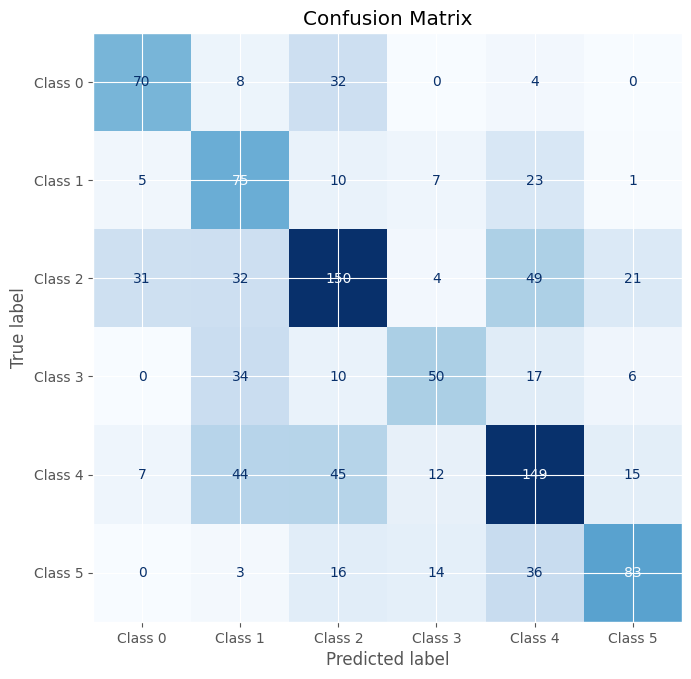

In [26]:
# Emo confusion matrix
emotion_labels = [
    f"Class {i}"
    for i in range(6)
]

cm = confusion_matrix(

    labels,

    predictions,

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=emotion_labels,

)

fig, ax = plt.subplots(

    figsize=(7,7)

)

disp.plot(

    cmap="Blues",

    ax=ax,

    colorbar=False,

)

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()

- Neutral and Excited/Happy remain the strongest.
- Happy and Excited still confuse each other.
- Sad and Neutral also overlap.

Quite expected on IEMOCAP.